In [3]:
import pandas as pd
import numpy as np

In [4]:
pd.read_csv(r"D:\vs\final project1\EHR\hospital_readmission_dataset.csv")

,patient_id,admission_date,season,age,gender,region,primary_diagnosis,comorbidities_count,length_of_stay,treatment_type,medications_count,followup_visits_last_year,prev_readmissions,insurance_type,discharge_disposition,readmission_risk_score,label
0,P00001,2022-04-14,Spring,66,Male,South,Diabetes,5,6,Interventional,8,6,1,Medicare,Home Health,0.92,1
1,P00002,2021-09-19,Fall,55,Male,South,Diabetes,4,6,Interventional,6,4,3,Private,Home Health,0.88,1
2,P00003,2023-04-12,Spring,69,Female,West,Hypertension,6,8,Medical,9,6,2,Medicare,Skilled Nursing,0.97,1
3,P00004,2023-08-14,Summer,83,Male,South,Stroke,6,11,Medical,11,4,2,Medicare,Skilled Nursing,0.97,1
4,P00005,2021-11-05,Fall,54,Female,North,Stroke,4,10,Medical,6,2,1,Uninsured,Home Health,0.83,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,P07996,2022-01-11,Winter,95,Female,East,COPD,6,9,Interventional,11,6,2,Medicare,Skilled Nursing,0.97,1
7996,P07997,2022-05-05,Spring,63,Female,East,Kidney Disease,4,7,Surgical,7,4,1,Medicaid,Home Health,0.94,1
7997,P07998,2021-08-26,Summer,43,Female,East,Diabetes,3,6,Medical,4,2,3,Uninsured,Home Health,0.79,1
7998,P07999,2021-04-20,Spring,86,Male,West,Sepsis,7,12,Interventional,12,5,3,Medicare,Skilled Nursing,0.97,1


In [5]:
df = pd.read_csv(r"D:\vs\final project1\EHR\hospital_readmission_dataset.csv")

In [6]:
df.shape

(8000, 17)

In [7]:
df.columns

Index(['patient_id', 'admission_date', 'season', 'age', 'gender', 'region',
       'primary_diagnosis', 'comorbidities_count', 'length_of_stay',
       'treatment_type', 'medications_count', 'followup_visits_last_year',
       'prev_readmissions', 'insurance_type', 'discharge_disposition',
       'readmission_risk_score', 'label'],
      dtype='object')

In [8]:
df.head()

,patient_id,admission_date,season,age,gender,region,primary_diagnosis,comorbidities_count,length_of_stay,treatment_type,medications_count,followup_visits_last_year,prev_readmissions,insurance_type,discharge_disposition,readmission_risk_score,label
0,P00001,2022-04-14,Spring,66,Male,South,Diabetes,5,6,Interventional,8,6,1,Medicare,Home Health,0.92,1
1,P00002,2021-09-19,Fall,55,Male,South,Diabetes,4,6,Interventional,6,4,3,Private,Home Health,0.88,1
2,P00003,2023-04-12,Spring,69,Female,West,Hypertension,6,8,Medical,9,6,2,Medicare,Skilled Nursing,0.97,1
3,P00004,2023-08-14,Summer,83,Male,South,Stroke,6,11,Medical,11,4,2,Medicare,Skilled Nursing,0.97,1
4,P00005,2021-11-05,Fall,54,Female,North,Stroke,4,10,Medical,6,2,1,Uninsured,Home Health,0.83,1


In [9]:
df = df.drop(['patient_id', 'readmission_risk_score'], axis=1)

In [10]:
df['admission_date'] = pd.to_datetime(df['admission_date'])

In [11]:
df['admission_month'] = df['admission_date'].dt.month
df['admission_dayofweek'] = df['admission_date'].dt.dayofweek

In [12]:
df = df.drop(['admission_date'], axis=1)

In [13]:
df.isnull().sum()

season                       0
age                          0
gender                       0
region                       0
primary_diagnosis            0
comorbidities_count          0
length_of_stay               0
treatment_type               0
medications_count            0
followup_visits_last_year    0
prev_readmissions            0
insurance_type               0
discharge_disposition        0
label                        0
admission_month              0
admission_dayofweek          0
dtype: int64

In [14]:
#Encoding
df = pd.get_dummies(df, drop_first=True)

In [15]:
# features and target
X = df.drop('label', axis=1)
y = df['label']

In [16]:
#split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [17]:
#Handle Imbalance
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

scale_pos_weight = neg / pos

In [18]:
#Identify Categorical Columns
cat_cols = X_train.select_dtypes(include=['object']).columns
print(cat_cols)

Index([], dtype='object')


In [19]:
#One-Hot Encoding
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

In [20]:
#Train and test
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [21]:
print(X_train.shape)
print(X_test.shape)

(6400, 35)
(1600, 35)


In [22]:
#Train Model
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)

In [23]:
model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [24]:
#Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [25]:
#Threshold Tuning
threshold = 0.4
y_pred_custom = (y_prob > threshold).astype(int)

In [26]:
#Evaluate
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print("=== 0.5 Threshold ===")
print(classification_report(y_test, y_pred))

print("=== 0.4 Threshold ===")
print(classification_report(y_test, y_pred_custom))

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_custom))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

=== 0.5 Threshold ===
              precision    recall  f1-score   support

           0       0.49      0.71      0.58       363
           1       0.90      0.78      0.84      1237

    accuracy                           0.76      1600
   macro avg       0.69      0.75      0.71      1600
weighted avg       0.81      0.76      0.78      1600

=== 0.4 Threshold ===
              precision    recall  f1-score   support

           0       0.51      0.59      0.55       363
           1       0.87      0.84      0.86      1237

    accuracy                           0.78      1600
   macro avg       0.69      0.71      0.70      1600
weighted avg       0.79      0.78      0.79      1600

Confusion Matrix:
 [[ 213  150]
 [ 201 1036]]
ROC-AUC: 0.821802949016883


In [27]:
from sklearn.metrics import RocCurveDisplay

from sklearn.metrics import (

    RocCurveDisplay,

    roc_auc_score
)


print(

    "ROC-AUC:",

    roc_auc_score(y_test, y_prob)
)

ROC-AUC: 0.821802949016883


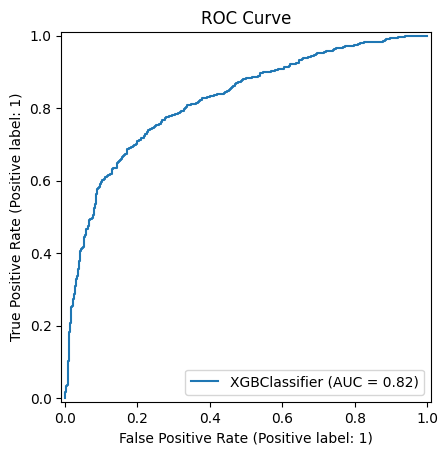

In [28]:
#ROC curve
import matplotlib.pyplot as plt

RocCurveDisplay.from_estimator(

    model,

    X_test,

    y_test
)
plt.title(

    "ROC Curve"
)

plt.show()

In [67]:
FINAL_THRESHOLD = 0.4

In [68]:
#Save
import joblib

joblib.dump(model, "readmission_model.pkl")
joblib.dump(X_train.columns, "model_columns.pkl")
joblib.dump(0.4, "threshold.pkl")

['threshold.pkl']

In [69]:
#Build Input Pipeline
def prepare_input(input_dict):
    import pandas as pd
    import joblib
    
    cols = joblib.load("model_columns.pkl")
    
    df = pd.DataFrame([input_dict])
    df = pd.get_dummies(df)
    
    df = df.reindex(columns=cols, fill_value=0)
    
    return df

In [70]:
#Final Prediction Engine
def predict_pipeline(input_dict):
    import joblib
    
    model = joblib.load("readmission_model.pkl")
    threshold = joblib.load("threshold.pkl")
    
    sample = prepare_input(input_dict)
    
    prob = model.predict_proba(sample)[:, 1][0]
    
    decision = "High Risk" if prob > threshold else "Low Risk"
    
    return prob, decision

In [71]:
#Explanation
def explain_risk(sample):
    reasons = []
    
    if sample['prev_readmissions'].values[0] > 2:
        reasons.append("Multiple previous readmissions")
    if sample['comorbidities_count'].values[0] > 3:
        reasons.append("Multiple comorbidities")
    if sample['length_of_stay'].values[0] < 3:
        reasons.append("Short hospital stay")
    if sample['medications_count'].values[0] > 5:
        reasons.append("High medication load")
    
    return reasons

In [72]:
#Final Test
new_patient = {
    'age': 65,
    'gender': 'Male',
    'comorbidities_count': 4,
    'medications_count': 6,
    'prev_readmissions': 3,
    'length_of_stay': 2,
    'season': 'Winter',
    'region': 'South',
    'treatment_type': 'Medical',
    'insurance_type': 'Private',
    'discharge_disposition': 'Home'
}

sample = prepare_input(new_patient)

prob, decision = predict_pipeline(new_patient)
reasons = explain_risk(sample)

print("Risk:", round(prob, 2))
print("Decision:", decision)
print("Reasons:", reasons)

Risk: 0.78
Decision: High Risk
Reasons: ['Multiple previous readmissions', 'Multiple comorbidities', 'Short hospital stay', 'High medication load']
